In [1]:
#[EDA01] Import libraries and load dataset

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df_eda = pd.read_csv(
    "../data/processed/air_quality_cleaned.csv",
    parse_dates=["datetime"]
)

In [2]:
#[EDA02] Inspect dataset dimensions and columns
df_eda.shape, df_eda.columns.tolist()

((43824, 16),
 ['year',
  'month',
  'day',
  'hour',
  'pm2.5',
  'DEWP',
  'TEMP',
  'PRES',
  'Iws',
  'Is',
  'Ir',
  'datetime',
  'cbwd_NE',
  'cbwd_NW',
  'cbwd_SE',
  'cbwd_cv'])

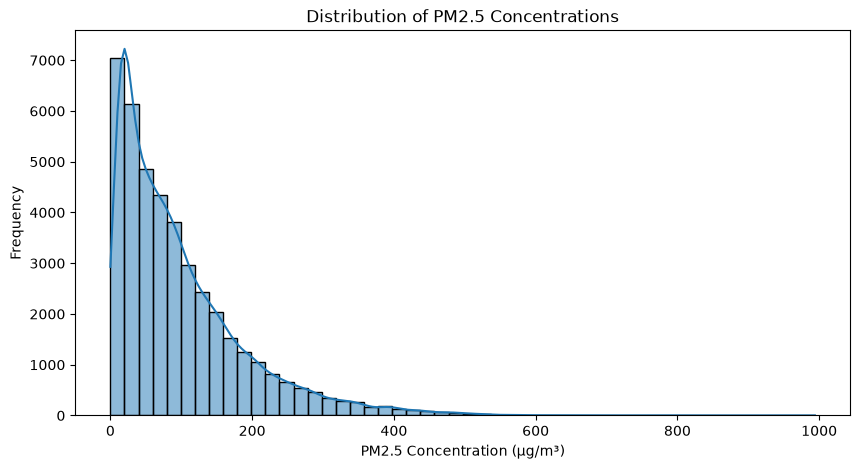

In [4]:
#[EDA03] Visualise PM2.5 distribution

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_eda,
    x="pm2.5",
    bins=50,
    kde=True
)

plt.title("Distribution of PM2.5 Concentrations")
plt.xlabel("PM2.5 Concentration (µg/m³)")
plt.ylabel("Frequency")
plt.show()

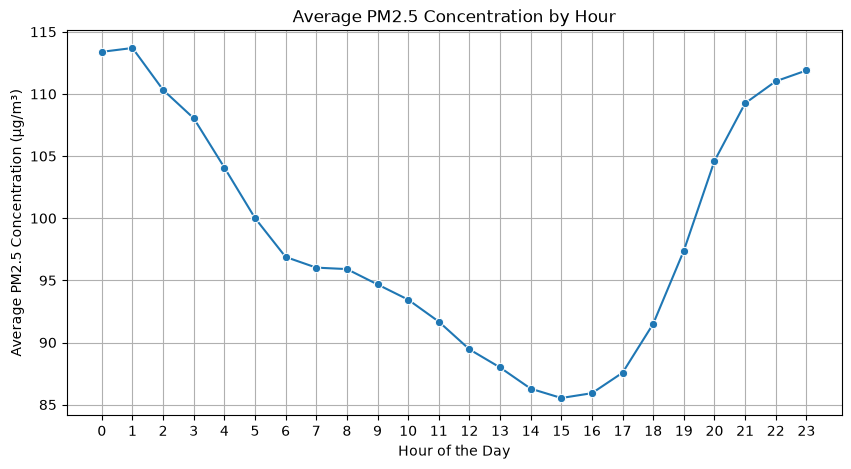

In [5]:
#[EDA04] Analyse hourly PM2.5 patterns

hourly_pm25 = df_eda.groupby("hour")["pm2.5"].mean()

plt.figure(figsize=(10, 5))

sns.lineplot(
    x=hourly_pm25.index,
    y=hourly_pm25.values,
    marker="o"
)

plt.title("Average PM2.5 Concentration by Hour")
plt.xlabel("Hour of the Day")
plt.ylabel("Average PM2.5 Concentration (µg/m³)")
plt.xticks(range(0, 24))
plt.grid(True)
plt.show()

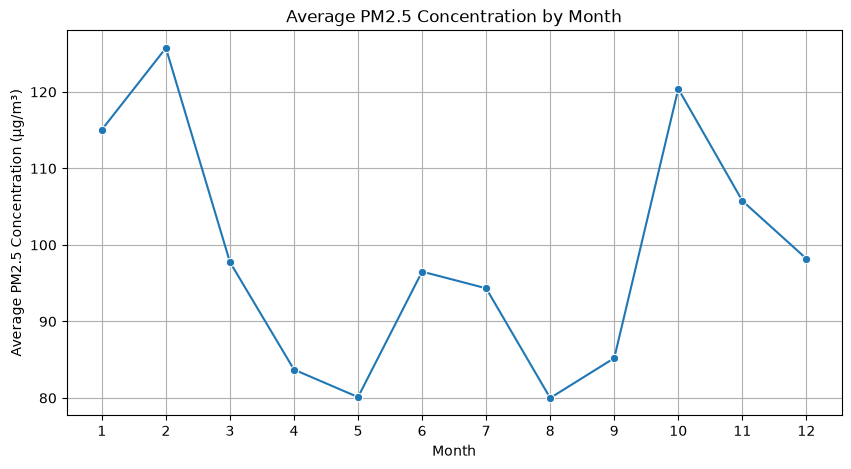

In [6]:
#[EDA05] Analyse monthly PM2.5 patterns

monthly_pm25 = df_eda.groupby("month")["pm2.5"].mean()

plt.figure(figsize=(10, 5))

sns.lineplot(
    x=monthly_pm25.index,
    y=monthly_pm25.values,
    marker="o"
)

plt.title("Average PM2.5 Concentration by Month")
plt.xlabel("Month")
plt.ylabel("Average PM2.5 Concentration (µg/m³)")
plt.xticks(range(1, 13))
plt.grid(True)
plt.show()

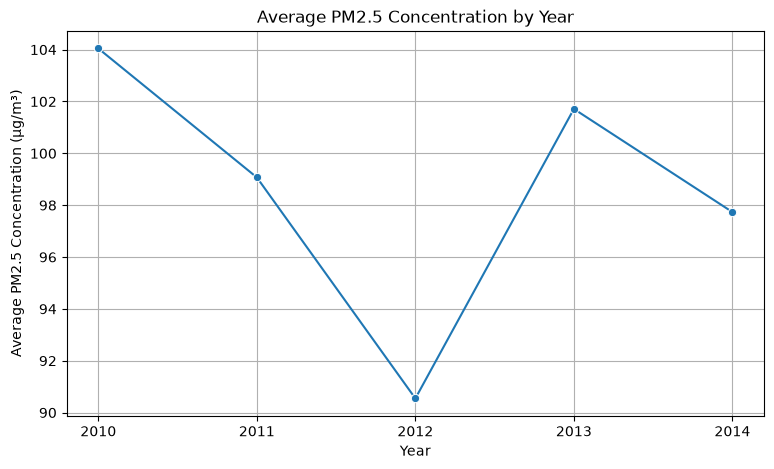

In [7]:
#[EDA06] Analyse yearly PM2.5 trends

yearly_pm25 = df_eda.groupby("year")["pm2.5"].mean()

plt.figure(figsize=(9, 5))

sns.lineplot(
    x=yearly_pm25.index,
    y=yearly_pm25.values,
    marker="o"
)

plt.title("Average PM2.5 Concentration by Year")
plt.xlabel("Year")
plt.ylabel("Average PM2.5 Concentration (µg/m³)")
plt.xticks(range(2010, 2015))
plt.grid(True)
plt.show()

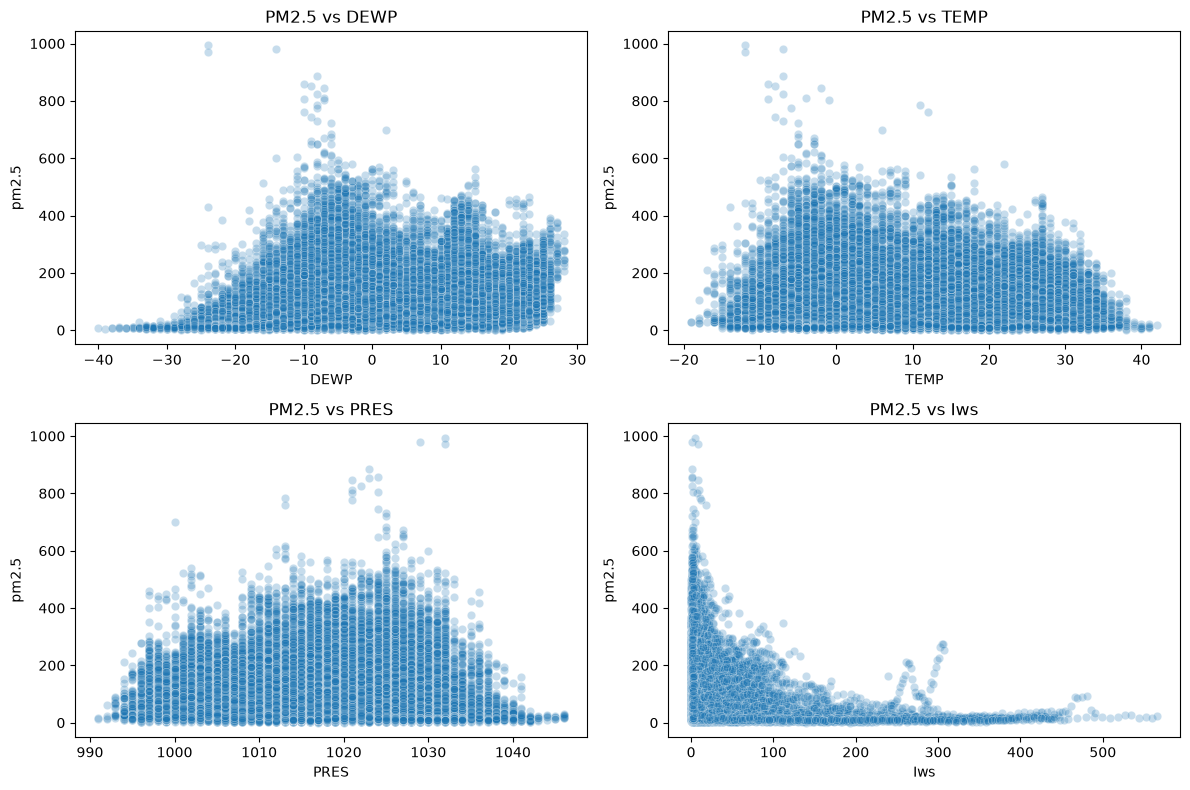

In [8]:
#[EDA07] Analyse weather relationships

weather_features = ["DEWP", "TEMP", "PRES", "Iws"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for feature, ax in zip(weather_features, axes.flatten()):
    sns.scatterplot(
        data=df_eda,
        x=feature,
        y="pm2.5",
        alpha=0.25,
        ax=ax
    )
    ax.set_title(f"PM2.5 vs {feature}")

plt.tight_layout()
plt.show()

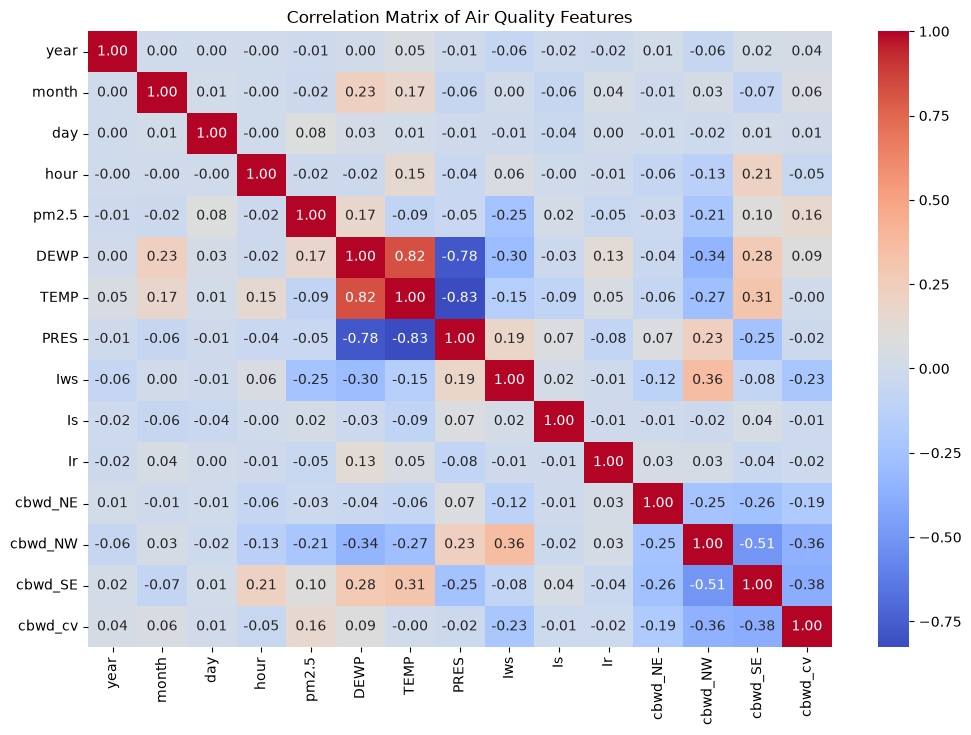

In [9]:
#[EDA08] Generate correlation heatmap

correlation_matrix = df_eda.drop(
    columns=["datetime"]
).corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix of Air Quality Features")
plt.show()

In [10]:
#[EDA09] Summarise EDA findings

print("EDA SUMMARY")
print("-----------")
print("PM2.5 distribution: Right-skewed")
print("Hourly pattern: Higher late-night and evening concentrations")
print("Yearly pattern: Considerable variation from 2010 to 2014")
print("Weather relationships: Mostly weak linear correlations")
print("Notable correlation: Wind speed and PM2.5 = -0.25")
print("Strong feature correlation: Temperature and pressure = -0.83")

EDA SUMMARY
-----------
PM2.5 distribution: Right-skewed
Hourly pattern: Higher late-night and evening concentrations
Yearly pattern: Considerable variation from 2010 to 2014
Weather relationships: Mostly weak linear correlations
Notable correlation: Wind speed and PM2.5 = -0.25
Strong feature correlation: Temperature and pressure = -0.83
